# U-Net Segmentation

A small encoder–decoder finds disks and rectangles under uneven lighting. A skip connection returns fine edges to the decoder.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## One-scale U-Net

The benchmark uses a compact teaching variant with one downsampling step and a skip concatenation.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from gallery.vision import shapes, binary_mask_scores
from gallery.neural import seed_cpu


class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.Conv2d(8, 8, 3, padding=1), nn.ReLU()
        )
        self.middle = nn.Sequential(nn.MaxPool2d(2), nn.Conv2d(8, 16, 3, padding=1), nn.ReLU())
        self.up = nn.ConvTranspose2d(16, 8, 2, stride=2)
        self.decoder = nn.Sequential(nn.Conv2d(16, 8, 3, padding=1), nn.ReLU(), nn.Conv2d(8, 1, 1))

    def forward(self, x):
        fine = self.encoder(x)
        return self.decoder(torch.cat([fine, self.up(self.middle(fine))], dim=1))

## Independent scenes

Binary cross-entropy uses a positive weight of 3 to account for foreground sparsity.

Mean IoU: 0.880
Mean Dice: 0.934
Pixel precision: 0.901
Pixel recall: 0.978
Pixel accuracy: 0.985


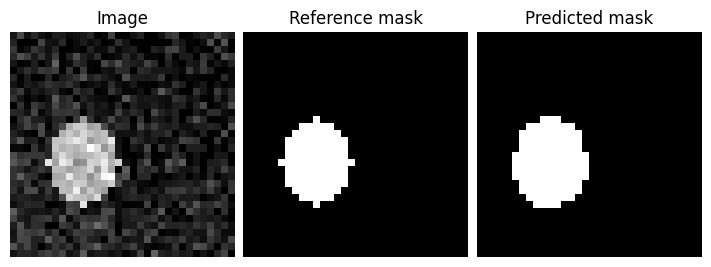

In [3]:
seed_cpu()
images, masks = shapes(320, 17)
test, reference = shapes(80, 71)
X = torch.tensor(images[:, None])
y = torch.tensor(masks[:, None], dtype=torch.float32)
net = SmallUNet()
opt = torch.optim.Adam(net.parameters(), lr=0.003)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(3.0))
for epoch in range(12):
    for batch in torch.randperm(len(X)).split(32):
        opt.zero_grad()
        loss = loss_fn(net(X[batch]), y[batch])
        loss.backward()
        opt.step()
net.eval()
with torch.no_grad():
    pred = net(torch.tensor(test[:, None]))[:, 0].numpy() > 0
for name, value in binary_mask_scores(reference, pred).items():
    print(f"{name}: {value:.3f}")
fig, axes = plt.subplots(1, 3, figsize=(7, 2.5), constrained_layout=True)
for a, im, label in zip(
    axes, [test[1], reference[1], pred[1]], ["Image", "Reference mask", "Predicted mask"]
):
    a.imshow(im, cmap="gray")
    a.set_title(label)
    a.axis("off")
plt.show()

## Reading the result

Pixel accuracy is dominated by background. Mean intersection over union and Dice give each test shape equal weight.

## References

[Ronneberger, Fischer and Brox, U-Net (2015)](https://arxiv.org/abs/1505.04597)

[Image and video generators and evaluation](../../../gallery/vision.py)